In [1]:
%load_ext autoreload
%autoreload 2
import glob
import cv2
import matplotlib.pyplot as plt
import numpy as np


from tflite_inference_baseline import TFLiteInferer, TFLiteMerged

2025-11-04 15:20:14.897116: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-11-04 15:20:14.913741: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-11-04 15:20:14.918766: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-11-04 15:20:14.931193: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-11-04 15:20:15.820570: W tensorflow/compiler/tf2

TensorFlow version:  2.17.0


In [2]:
tst_img_path = "../../../rtos_sensor/projects/alif_ml-embedded-evaluation-kit_pg/resources/pg_object_detection/samples/img_320.bmp"

img = cv2.cvtColor(cv2.imread(tst_img_path), cv2.COLOR_BGR2RGB)

ORIGINAL_H, ORIGIAL_W, _ = img.shape
W = H = 320
RATIO = W / ORIGIAL_W

In [3]:
def draw(img, fp32_dets=None, uint8_dets=None, uint8_biased_dets=None):
    tmp = img.copy()
    
    # Define colors for each detection type
    colors = {
        'fp32': (255, 0, 0),      # Red
        'uint8': (0, 255, 0),     # Green
        'uint8_biased': (0, 0, 255)  # Blue
    }
    
    # Draw each type of detection
    if fp32_dets is not None:
        for box in fp32_dets:
            cv2.rectangle(tmp, (box[:2]).astype(int), ((box[:2].astype(int) + box[2:4])).astype(int), colors['fp32'], 1)
        for p in fp32_dets:
            cv2.circle(tmp, (p[-2:]).astype(int), 2, colors['fp32'], 3)
    
    if uint8_dets is not None:
        for box in uint8_dets:
            cv2.rectangle(tmp, (box[:2]).astype(int), ((box[:2].astype(int) + box[2:4])).astype(int), colors['uint8'], 1)
        for p in uint8_dets:
            cv2.circle(tmp, (p[-2:]).astype(int), 2, colors['uint8'], 3)
    
    if uint8_biased_dets is not None:
        for box in uint8_biased_dets:
            cv2.rectangle(tmp, (box[:2]).astype(int), ((box[:2].astype(int) + box[2:4])).astype(int), colors['uint8_biased'], 1)
        for p in uint8_biased_dets:
            cv2.circle(tmp, (p[-2:]).astype(int), 2, colors['uint8_biased'], 3)
    
    # Add legend at top left corner with white background
    legend_x = 5
    legend_y = 5
    legend_spacing = 10
    legend_width = 70
    legend_height = 32
    
    # Draw white background for legend
    cv2.rectangle(tmp, (legend_x - 2, legend_y - 2), (legend_x + legend_width, legend_y + legend_height), (255, 255, 255), -1)
    
    cv2.rectangle(tmp, (legend_x, legend_y), (legend_x + 7, legend_y + 7), colors['fp32'], -1)
    cv2.putText(tmp, 'FP32', (legend_x + 10, legend_y + 6), cv2.FONT_HERSHEY_SIMPLEX, 0.25, (0, 0, 0), 1, cv2.LINE_AA)
    
    cv2.rectangle(tmp, (legend_x, legend_y + legend_spacing), (legend_x + 7, legend_y + legend_spacing + 7), colors['uint8'], -1)
    cv2.putText(tmp, 'UINT8', (legend_x + 10, legend_y + legend_spacing + 6), cv2.FONT_HERSHEY_SIMPLEX, 0.25, (0, 0, 0), 1, cv2.LINE_AA)
    
    cv2.rectangle(tmp, (legend_x, legend_y + 2*legend_spacing), (legend_x + 7, legend_y + 2*legend_spacing + 7), colors['uint8_biased'], -1)
    cv2.putText(tmp, 'UINT8+Bias', (legend_x + 10, legend_y + 2*legend_spacing + 6), cv2.FONT_HERSHEY_SIMPLEX, 0.25, (0, 0, 0), 1, cv2.LINE_AA)
    
    plt.figure(figsize=(8, 8))
    plt.imshow(tmp)

In [11]:

inferer = TFLiteInferer(
    yolo_pth="../results/cam3_revB_batch1_5_margin_15_rq_bg_wb_alif_clahe_box_01_dfl_01_2nd/weights/best_saved_model/best_full_integer_quant.tflite",
    head_pth="../results/cam3_revB_batch1_5_margin_15_rq_bg_wb_alif_clahe_box_01_dfl_01_2nd/weights/head_saved_model/head_float32.tflite",
)

fp32_dets = inferer.infer(img)

In [12]:

inferer = TFLiteMerged(
    yolo_pth="../results/cam3_revB_batch1_5_margin_15_rq_bg_wb_alif_clahe_box_01_dfl_01_2nd/weights/best_non_separated_saved_model_full_npu/best_full_integer_quant.tflite",
    iou_th=0.35,
    conf_th=0.4,
)

uint8_dets = inferer.infer(img)

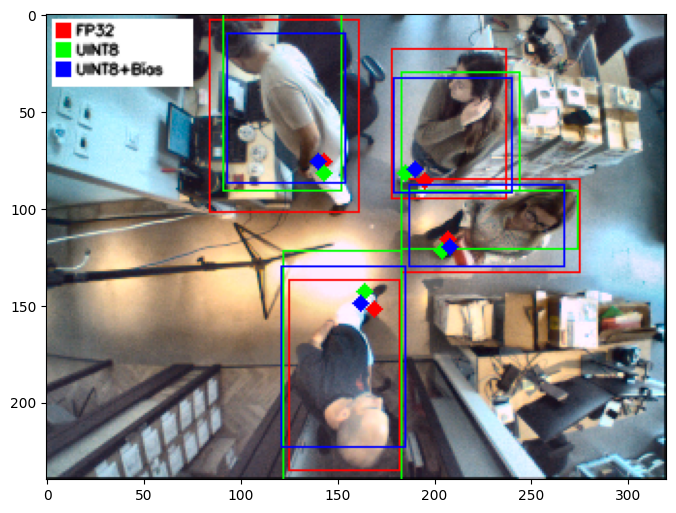

In [13]:

inferer = TFLiteMerged(
    yolo_pth="../results/cam3_revB_batch1_5_margin_15_rq_bg_wb_alif_clahe_box_01_dfl_01_2nd/weights/best_non_separated_saved_model_full_npu/best_full_integer_quant.tflite",
    bias_pth="wb_alif_clahe_ridge_regression_params_tiny.json",
    iou_th=0.35,
    conf_th=0.4,
)

uint8_biased_dets = inferer.infer(img)

draw(img, fp32_dets, uint8_dets, uint8_biased_dets)